<a href="https://colab.research.google.com/github/garvitSharma24112/machine-learning/blob/main/hierachichal_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Load and Inspect the Dataset
We will start by importing the necessary libraries, loading the CSV file, and displaying its basic structure.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering
import os

# Fallback standard path or verified download link
csv_path = '/kaggle/input/customer-segmentation-tutorial-in-python/Mall_Customers.csv'
if not os.path.exists(csv_path):
    print("Kaggle path not found. Downloading the Mall_Customers dataset from a verified repository...")
    csv_path = 'https://raw.githubusercontent.com/tirthajyoti/Machine-Learning-with-Python/master/Datasets/Mall_Customers.csv'

# Load the dataset
df = pd.read_csv(csv_path)
display(df.head())
display(df.info())

Kaggle path not found. Downloading the Mall_Customers dataset from a verified repository...


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


None

### Dendrogram to Determine Clusters
Typically, for customer segmentation in this dataset, 'Annual Income (k$)' and 'Spending Score (1-100)' are used. We will extract these features and plot a dendrogram to find the optimal number of clusters.

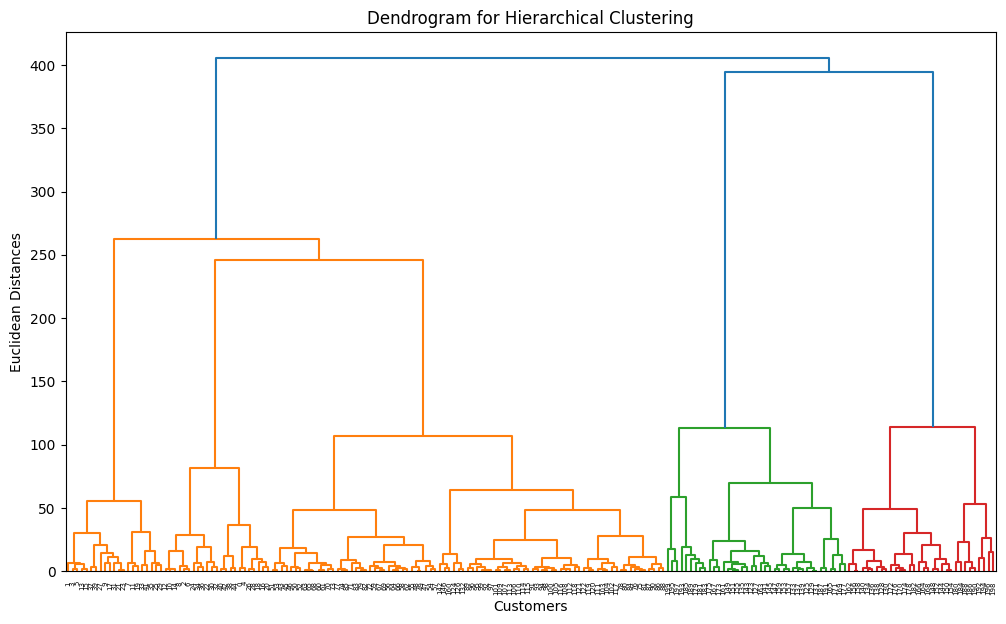

In [6]:
# Extract features: Annual Income (column index 3) and Spending Score (column index 4)
X = df.iloc[:, [3, 4]].values

# Plot the Dendrogram
plt.figure(figsize=(12, 7))
dendrogram = sch.dendrogram(sch.linkage(X, method='ward'))
plt.title('Dendrogram for Hierarchical Clustering')
plt.xlabel('Customers')
plt.ylabel('Euclidean Distances')
plt.show()

### Apply Hierarchical (Agglomerative) Clustering
Based on the dendrogram, 5 clusters are usually optimal for this dataset. We will train the Agglomerative Clustering model with 5 clusters and visualize the segmented customer groups.

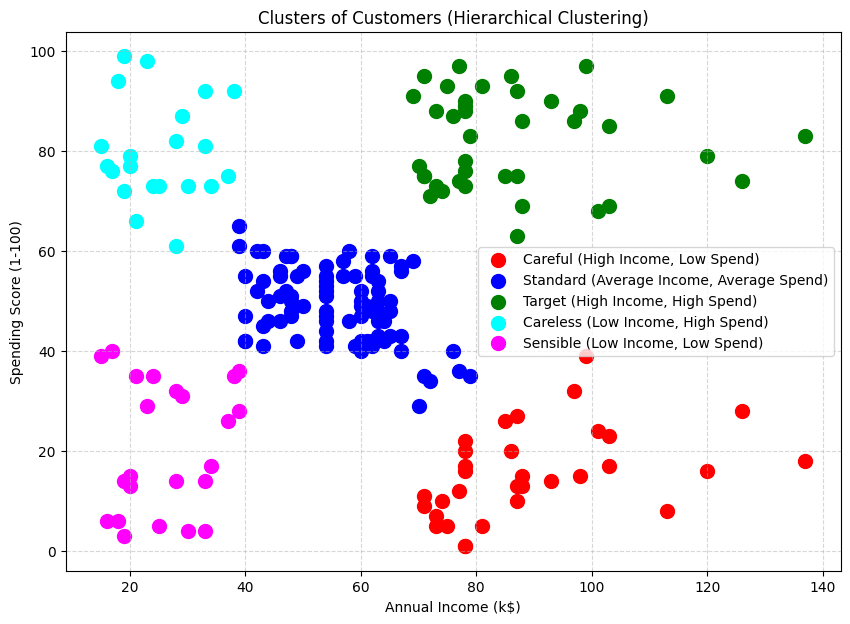

In [7]:
# Fitting Agglomerative Clustering to the dataset
hc = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(X)

# Visualizing the clusters
plt.figure(figsize=(10, 7))
plt.scatter(X[y_hc == 0, 0], X[y_hc == 0, 1], s=100, c='red', label='Careful (High Income, Low Spend)')
plt.scatter(X[y_hc == 1, 0], X[y_hc == 1, 1], s=100, c='blue', label='Standard (Average Income, Average Spend)')
plt.scatter(X[y_hc == 2, 0], X[y_hc == 2, 1], s=100, c='green', label='Target (High Income, High Spend)')
plt.scatter(X[y_hc == 3, 0], X[y_hc == 3, 1], s=100, c='cyan', label='Careless (Low Income, High Spend)')
plt.scatter(X[y_hc == 4, 0], X[y_hc == 4, 1], s=100, c='magenta', label='Sensible (Low Income, Low Spend)')

plt.title('Clusters of Customers (Hierarchical Clustering)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()